# Exploratory Data Analysis (EDA) Project
# Phase 2 — Hierarchical Clustering

**Name:** ANINDO PRITOM BARUA  
**Registration Number:** 23BDS0328  
**Course:** Exploratory Data Analysis (EDA)  
**Dataset:** Indian Food Dataset

## Objective

The objective of this notebook is to perform hierarchical clustering on the Indian Food dataset. Recipes will be grouped according to similarities in their preparation time, cooking time, and total time.

The numerical variables will first be standardized. An agglomerative hierarchical clustering approach will then be applied using different linkage methods. A dendrogram will be used to visualize the hierarchical structure and determine an appropriate number of clusters. The resulting clusters will be analyzed and visualized.

PHASE 2 - HIERARCHICAL CLUSTERING

Dataset loaded successfully.
Rows    : 255
Columns : 20

FEATURES USED FOR CLUSTERING
['prep_time', 'cook_time', 'total_time']

Number of observations: 255

STANDARDIZED DATA


,prep_time,cook_time,total_time
0,-0.222420,-0.094028,-0.222914
1,-0.291469,0.217363,-0.114888
2,-0.291469,0.321160,-0.060876
3,-0.291469,0.321160,-0.060876
4,-0.222420,0.840146,0.263201
5,0.191876,-0.197825,0.047150
6,-0.360519,0.009769,-0.276927
7,-0.291469,0.009769,-0.222914
8,-0.153371,0.528754,0.155176
9,0.675221,-0.094028,0.479253



LINKAGE METHODS
Calculating single linkage...
Calculating complete linkage...
Calculating average linkage...
Calculating ward linkage...
Linkage calculations ready.


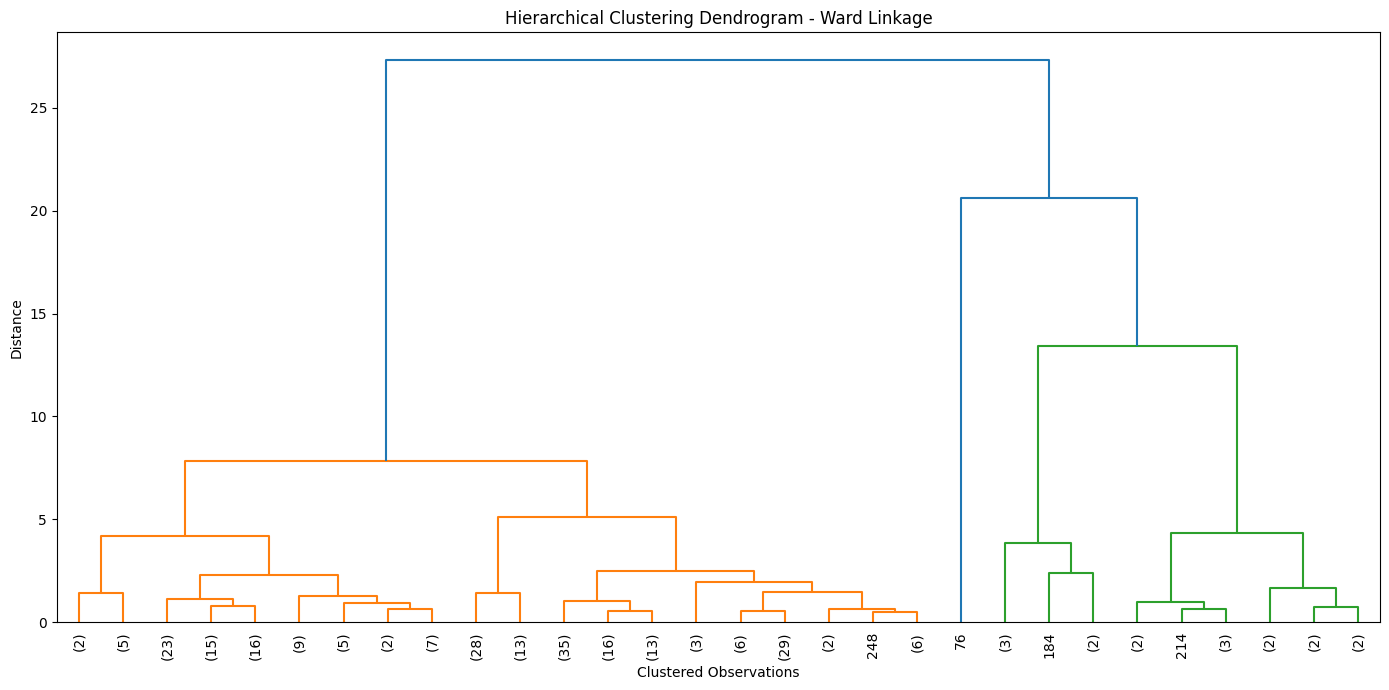

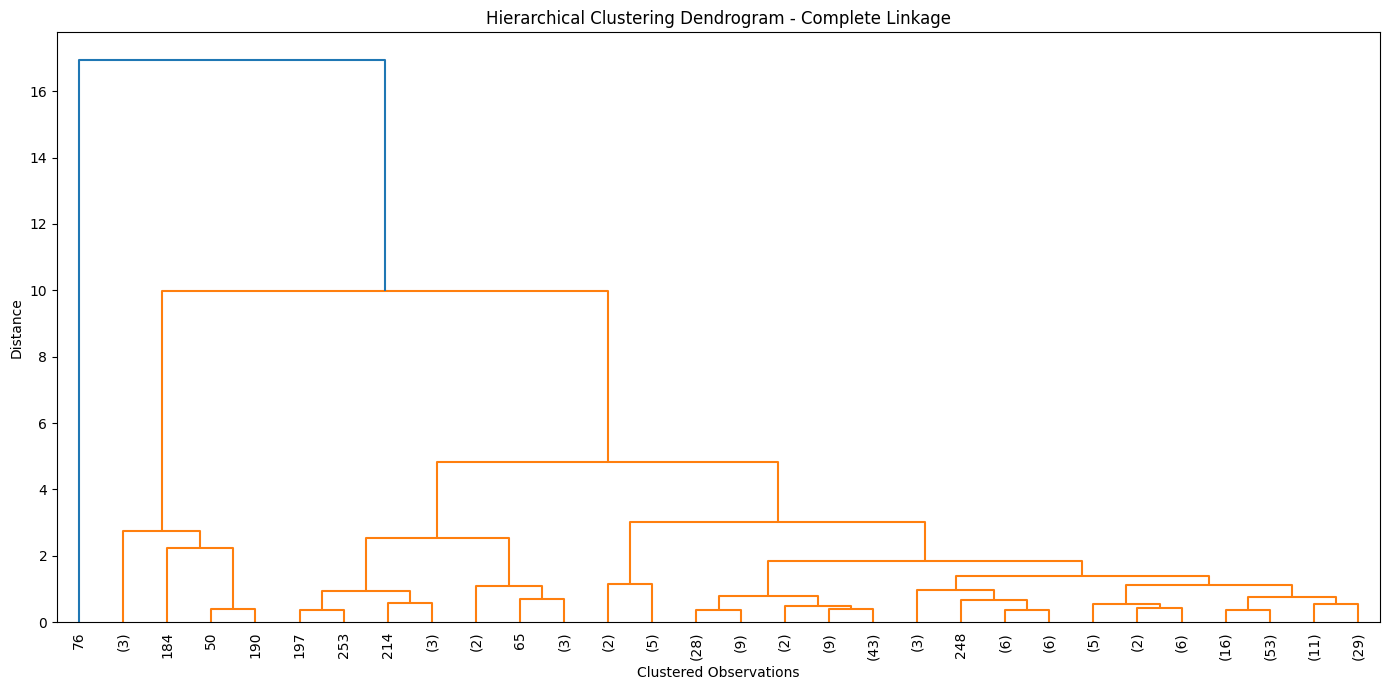


LINKAGE METHOD COMPARISON


,Linkage Method,Number of Clusters,Silhouette Score
0,single,3,0.872508
1,complete,3,0.872508
2,average,3,0.872508
3,ward,3,0.814186



SELECTED LINKAGE METHOD
Best linkage method : single
Silhouette score    : 0.8725

CLUSTER SIZES


,Number of Recipes
Cluster,
0,6
1,1
2,248



CLUSTER PROFILE


,prep_time,cook_time,total_time,Recipe_Count
Cluster,,,,
0,425.83,76.67,502.50,6
1,10.00,720.00,730.00,1
2,21.64,30.75,52.39,248


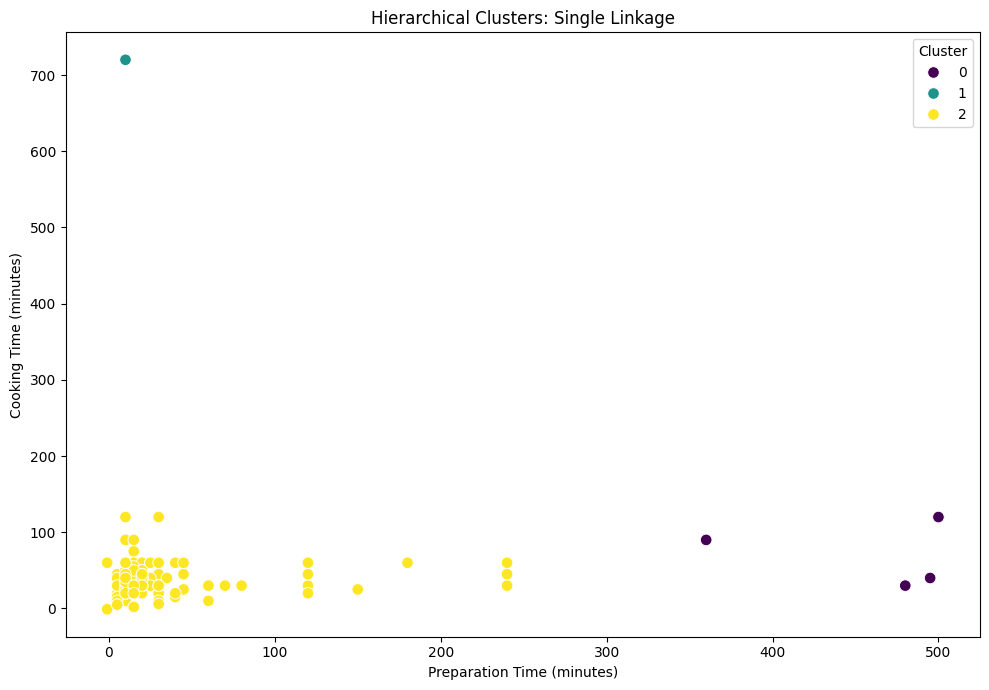

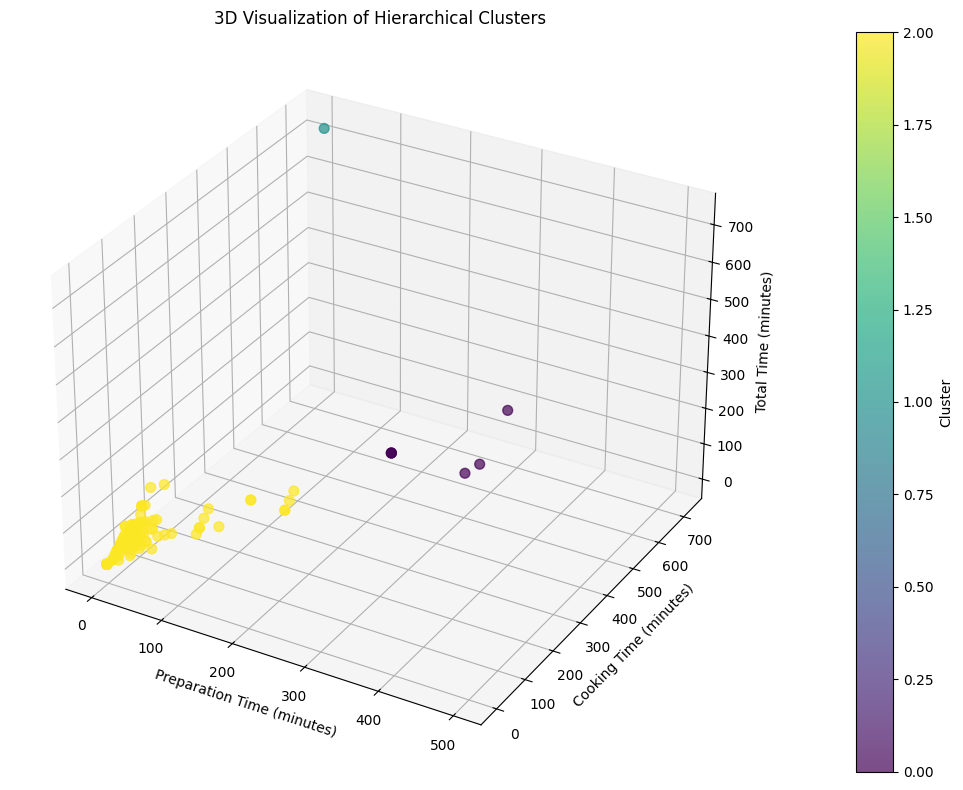

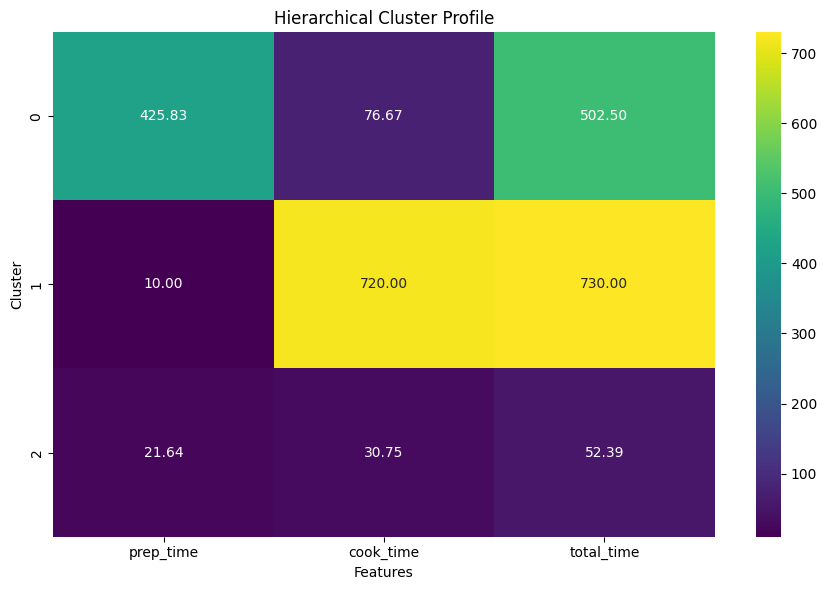


CLUSTER NUMBER COMPARISON


,Number of Clusters,Silhouette Score
0,2,0.924453
1,3,0.872508
2,4,0.849323
3,5,0.851129
4,6,0.800124


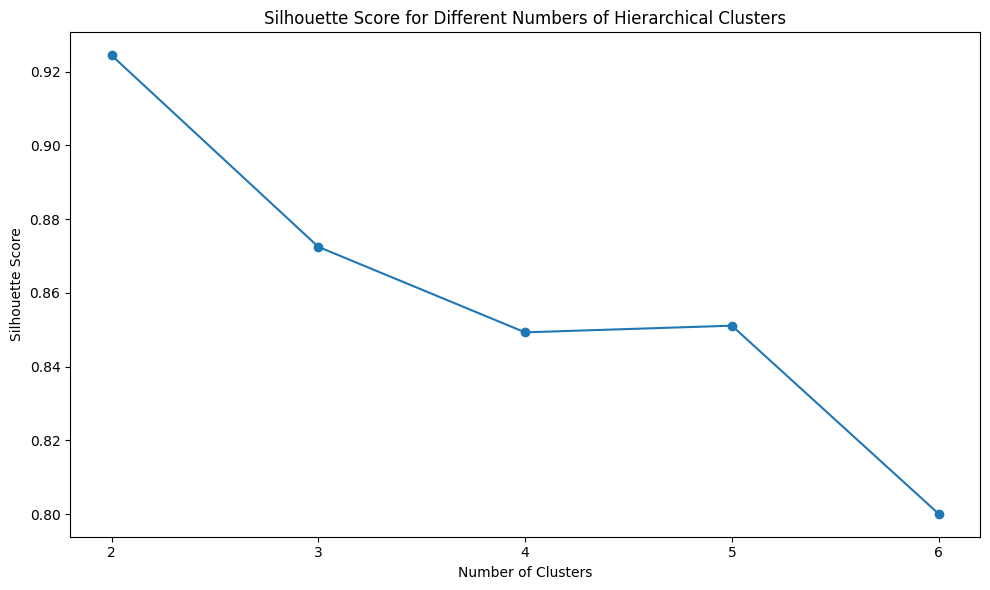


FINAL HIERARCHICAL CLUSTERING SUMMARY
Selected linkage method: single
Number of clusters: 3
Silhouette score: 0.8725
Clustered dataset saved as: indian_food_hierarchical_clustered.csv

HIERARCHICAL CLUSTERING COMPLETED


In [1]:
# ============================================================
# PHASE 2 - HIERARCHICAL CLUSTERING
# Name        : ANINDO PRITOM BARUA
# Registration: 23BDS0328
# Dataset     : Indian Food Dataset
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import (
    dendrogram,
    linkage,
    fcluster
)

# ------------------------------------------------------------
# 1. Load the transformed dataset
# ------------------------------------------------------------

file_path = "indian_food_transformed.csv"

df = pd.read_csv(file_path)

print("=" * 75)
print("PHASE 2 - HIERARCHICAL CLUSTERING")
print("=" * 75)

print("\nDataset loaded successfully.")
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])


# ------------------------------------------------------------
# 2. Select clustering variables
# ------------------------------------------------------------

features = [
    "prep_time",
    "cook_time",
    "total_time"
]

clustering_data = df[features].copy()

# Remove missing values
clustering_data = clustering_data.dropna()

print("\nFEATURES USED FOR CLUSTERING")
print("=" * 75)

print(features)

print("\nNumber of observations:", len(clustering_data))


# ------------------------------------------------------------
# 3. Standardize the variables
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    clustering_data
)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

print("\nSTANDARDIZED DATA")
print("=" * 75)

display(X_scaled_df.head(10))


# ------------------------------------------------------------
# 4. Generate linkage matrices
# ------------------------------------------------------------

print("\nLINKAGE METHODS")
print("=" * 75)

linkage_methods = [
    "single",
    "complete",
    "average",
    "ward"
]

for method in linkage_methods:

    print(f"Calculating {method} linkage...")

print("Linkage calculations ready.")


# ------------------------------------------------------------
# 5. Visualization 1
# Dendrogram - Ward Linkage
# ------------------------------------------------------------

plt.figure(figsize=(14, 7))

ward_linkage = linkage(
    X_scaled,
    method="ward"
)

dendrogram(
    ward_linkage,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title(
    "Hierarchical Clustering Dendrogram - Ward Linkage"
)

plt.xlabel("Clustered Observations")
plt.ylabel("Distance")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Visualization 2
# Dendrogram - Complete Linkage
# ------------------------------------------------------------

plt.figure(figsize=(14, 7))

complete_linkage = linkage(
    X_scaled,
    method="complete"
)

dendrogram(
    complete_linkage,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title(
    "Hierarchical Clustering Dendrogram - Complete Linkage"
)

plt.xlabel("Clustered Observations")
plt.ylabel("Distance")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Compare Linkage Methods using Silhouette Score
# ------------------------------------------------------------

print("\nLINKAGE METHOD COMPARISON")
print("=" * 75)

n_clusters = 3

linkage_results = []

for method in linkage_methods:

    # Ward linkage requires Euclidean distance,
    # which is appropriate for these standardized features.

    model = AgglomerativeClustering(
        n_clusters=n_clusters,
        linkage=method
    )

    labels = model.fit_predict(
        X_scaled
    )

    score = silhouette_score(
        X_scaled,
        labels
    )

    linkage_results.append({
        "Linkage Method": method,
        "Number of Clusters": n_clusters,
        "Silhouette Score": score
    })

linkage_table = pd.DataFrame(
    linkage_results
)

display(
    linkage_table.sort_values(
        "Silhouette Score",
        ascending=False
    )
)


# ------------------------------------------------------------
# 8. Select linkage method
# ------------------------------------------------------------

best_method = linkage_table.loc[
    linkage_table["Silhouette Score"].idxmax(),
    "Linkage Method"
]

best_score = linkage_table["Silhouette Score"].max()

print("\nSELECTED LINKAGE METHOD")
print("=" * 75)

print("Best linkage method :", best_method)
print("Silhouette score    :", round(best_score, 4))


# ------------------------------------------------------------
# 9. Apply Final Hierarchical Clustering
# ------------------------------------------------------------

final_model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage=best_method
)

cluster_labels = final_model.fit_predict(
    X_scaled
)

clustering_data["Cluster"] = cluster_labels


# ------------------------------------------------------------
# 10. Cluster Sizes
# ------------------------------------------------------------

print("\nCLUSTER SIZES")
print("=" * 75)

cluster_sizes = (
    clustering_data["Cluster"]
    .value_counts()
    .sort_index()
)

display(
    cluster_sizes.to_frame(
        name="Number of Recipes"
    )
)


# ------------------------------------------------------------
# 11. Cluster Profile
# ------------------------------------------------------------

print("\nCLUSTER PROFILE")
print("=" * 75)

cluster_profile = (
    clustering_data
    .groupby("Cluster")[features]
    .mean()
    .round(2)
)

cluster_profile["Recipe_Count"] = (
    clustering_data
    .groupby("Cluster")
    .size()
)

display(
    cluster_profile
)


# ------------------------------------------------------------
# 12. Visualization 3
# 2D Hierarchical Cluster Visualization
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=clustering_data,
    x="prep_time",
    y="cook_time",
    hue="Cluster",
    palette="viridis",
    s=70
)

plt.title(
    f"Hierarchical Clusters: {best_method.title()} Linkage"
)

plt.xlabel(
    "Preparation Time (minutes)"
)

plt.ylabel(
    "Cooking Time (minutes)"
)

plt.legend(
    title="Cluster"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. Visualization 4
# 3D Hierarchical Cluster Visualization
# ------------------------------------------------------------

fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(
    111,
    projection="3d"
)

scatter = ax.scatter(
    clustering_data["prep_time"],
    clustering_data["cook_time"],
    clustering_data["total_time"],
    c=clustering_data["Cluster"],
    cmap="viridis",
    s=50,
    alpha=0.7
)

ax.set_title(
    "3D Visualization of Hierarchical Clusters"
)

ax.set_xlabel(
    "Preparation Time (minutes)"
)

ax.set_ylabel(
    "Cooking Time (minutes)"
)

ax.set_zlabel(
    "Total Time (minutes)"
)

plt.colorbar(
    scatter,
    ax=ax,
    pad=0.1,
    label="Cluster"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. Visualization 5
# Cluster Profile Heatmap
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

profile_for_heatmap = cluster_profile[
    features
]

sns.heatmap(
    profile_for_heatmap,
    annot=True,
    fmt=".2f",
    cmap="viridis"
)

plt.title(
    "Hierarchical Cluster Profile"
)

plt.xlabel(
    "Features"
)

plt.ylabel(
    "Cluster"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. Compare number of clusters
# ------------------------------------------------------------

print("\nCLUSTER NUMBER COMPARISON")
print("=" * 75)

cluster_comparison = []

for k in range(2, 7):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage=best_method
    )

    labels = model.fit_predict(
        X_scaled
    )

    score = silhouette_score(
        X_scaled,
        labels
    )

    cluster_comparison.append({
        "Number of Clusters": k,
        "Silhouette Score": score
    })

cluster_comparison_df = pd.DataFrame(
    cluster_comparison
)

display(
    cluster_comparison_df
)


# ------------------------------------------------------------
# 16. Visualization 6
# Silhouette Score vs Number of Clusters
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    cluster_comparison_df["Number of Clusters"],
    cluster_comparison_df["Silhouette Score"],
    marker="o"
)

plt.title(
    "Silhouette Score for Different Numbers of Hierarchical Clusters"
)

plt.xlabel(
    "Number of Clusters"
)

plt.ylabel(
    "Silhouette Score"
)

plt.xticks(
    range(2, 7)
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 17. Create final clustered dataset
# ------------------------------------------------------------

df_clustered = df.loc[
    clustering_data.index
].copy()

df_clustered["Hierarchical_Cluster"] = cluster_labels


# ------------------------------------------------------------
# 18. Save clustered dataset
# ------------------------------------------------------------

output_file = (
    "indian_food_hierarchical_clustered.csv"
)

df_clustered.to_csv(
    output_file,
    index=False
)


# ------------------------------------------------------------
# 19. Final Summary
# ------------------------------------------------------------

print("\nFINAL HIERARCHICAL CLUSTERING SUMMARY")
print("=" * 75)

print(
    "Selected linkage method:",
    best_method
)

print(
    "Number of clusters:",
    n_clusters
)

print(
    "Silhouette score:",
    round(best_score, 4)
)

print(
    "Clustered dataset saved as:",
    output_file
)

print("\n" + "=" * 75)
print("HIERARCHICAL CLUSTERING COMPLETED")
print("=" * 75)

## Conclusion

Hierarchical clustering was successfully applied to the Indian Food dataset using preparation time, cooking time, and total time as clustering features.

The numerical variables were standardized before clustering. Dendrograms were generated using different linkage approaches to examine the hierarchical structure of the observations. Single, complete, average, and Ward linkage methods were compared using silhouette scores.

The selected hierarchical clustering model grouped recipes according to similarities in their preparation and cooking characteristics. Cluster sizes and cluster profiles were calculated to understand the characteristics of each group.

Two-dimensional and three-dimensional visualizations were used to examine the resulting clusters, while a cluster-profile heatmap provided a comparison of the average characteristics of each cluster.

The final hierarchical clustering results were saved as `indian_food_hierarchical_clustered.csv`.

This completes the required Phase 2 statistical analysis and clustering techniques, including 1D analysis, 2D analysis, 3D analysis, K-Means clustering, and Hierarchical clustering.